# Laboratório de Ciência de Dados aplicado ao Jornalismo Esportivo
### Avaliação de Segunda Chamada · Jornalismo Esportivo · CEUB

| Campo | Informação |
|---|---|
| **Estudante** | _Nicolas Balzon_ |
| **Professora** | Kadidja Valéria |
| **Ferramenta** | Google Colab e Python (pandas, numpy, matplotlib, seaborn) |
| **Base de dados** | `conteudos_jornalismo_esportivo.csv` (60 conteúdos, set–out/2026, base fictícia) |

**Pergunta-guia:** quais características dos conteúdos esportivos estão associadas ao maior alcance, engajamento, retenção, geração de cliques e conversão de assinantes?

> Princípio editorial: os dados apoiam a decisão, mas **não substituem** os critérios de relevância, interesse público, diversidade, precisão e responsabilidade.

**Roteiro do notebook:** 1) Carregamento e diagnóstico → 2) Tratamento → 3) Métricas → 4) Análise por grupos → 5) Visualizações → 6) Questões 1 a 8 → 7) Conclusão e limitações → 8) Discussão de fechamento.

**Como ler o notebook:** cada bloco de código traz comentários; as respostas às questões vêm logo abaixo das saídas, separando **evidência** (o que os números mostram), **hipótese** (explicação possível, ainda não testada) e **recomendação** (o que fazer).

## Compreensão do problema
O portal publica notícias, análises, entrevistas, reportagens e vídeos de várias modalidades. A equipe editorial quer saber **quais conteúdos funcionam melhor e por quê**, para orientar pauta, formato, horário e distribuição.

Três perguntas orientam a análise:
1. Quem tem **alcance** (visualizações) é também quem tem **engajamento** e **conversão**?
2. **Formato, modalidade e turno** mudam o desempenho?
3. O que os dados **não** conseguem responder?

Regra de ouro do enunciado: *muitas visualizações não significam, necessariamente, mais relevância, engajamento, retenção ou conversão.*

## Etapa 1 · Carregamento e diagnóstico
Carregamos o CSV, guardamos uma cópia da base original (`df_original`) e verificamos dimensão, tipos, ausências, duplicados e categorias inconsistentes.

In [1]:
# ============================================================
# ETAPA 1 – CARREGAMENTO E DIAGNÓSTICO
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo visual padronizado (cores legíveis e contrastantes)
sns.set_theme(style="whitegrid", context="notebook")
PALETA = ["#4B0A4F", "#D4007F", "#2E86AB", "#F2A541", "#6A994E", "#8A8A8A"]
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

ARQUIVO = "conteudos_jornalismo_esportivo.csv"

# No Google Colab, se o arquivo ainda não estiver no ambiente, abre o seletor de upload
if not os.path.exists(ARQUIVO):
    from google.colab import files
    files.upload()

# Carrega a base bruta
df = pd.read_csv(ARQUIVO)

# Preserva uma cópia intocada da base original (todo o tratamento será feito em "dados")
df_original = df.copy()

# Cinco primeiras linhas
display(df.head())

,data_publicacao,portal,titulo,modalidade,tipo_conteudo,turno_publicacao,visualizacoes,usuarios_unicos,tempo_medio_segundos,curtidas,comentarios,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria
0,2026-09-29,App,Futebol: resultado e principais lances da rodada #01,Futebol,Notícia,Noite,112837,90617,66,2264,331,537,9299,140,"1,167.51"
1,2026-10-21,YouTube,Basquete: reportagem sobre os bastidores do esporte #02,Basquete,Reportagem,Tarde,7804,6312,332,171,20,72,666,39,64.46
2,2026-09-27,App,Vôlei: resultado e principais lances da rodada #03,Vôlei,Notícia,Tarde,19993,17158,87,504,59,120,1583,13,186.49
3,2026-10-13,Portal Web,Automobilismo: análise tática da semana #04,Automobilismo,Análise,Manhã,6703,5073,210,147,18,50,661,19,60.62
4,2026-10-06,Instagram,Tênis: análise tática da semana #05,Tênis,Análise,Noite,6937,6600,180,227,29,48,1010,48,51.10


In [2]:
# Dimensão da base
print("Registros (linhas):", df.shape[0])
print("Variáveis (colunas):", df.shape[1])

# Tipos de dados e preenchimento de cada coluna
print("\n--- Estrutura (info) ---")
df.info()

# Valores ausentes por coluna
print("\n--- Valores ausentes ---")
ausentes = df.isna().sum()
print(ausentes[ausentes > 0] if ausentes.sum() > 0 else "Nenhum")

# Registros duplicados (linha inteira e título)
print("\nLinhas duplicadas:", df.duplicated().sum())
print("Títulos duplicados:", df["titulo"].duplicated().sum())

# repr() revela espaços invisíveis nas categorias (ex.: 'Vôlei ' vs 'Vôlei')
print("\n--- Categorias de modalidade (com repr) ---")
print(df["modalidade"].apply(repr).value_counts())

# Demais categóricas
for col in ["portal", "tipo_conteudo", "turno_publicacao"]:
    print(f"\n{col}:", sorted(df[col].apply(repr).unique()))

Registros (linhas): 60
Variáveis (colunas): 15

--- Estrutura (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   data_publicacao       60 non-null     str    
 1   portal                60 non-null     str    
 2   titulo                60 non-null     str    
 3   modalidade            60 non-null     str    
 4   tipo_conteudo         60 non-null     str    
 5   turno_publicacao      60 non-null     str    
 6   visualizacoes         60 non-null     int64  
 7   usuarios_unicos       60 non-null     int64  
 8   tempo_medio_segundos  60 non-null     int64  
 9   curtidas              60 non-null     int64  
 10  comentarios           60 non-null     int64  
 11  compartilhamentos     60 non-null     int64  
 12  cliques_relacionados  60 non-null     int64  
 13  novos_assinantes      60 non-null     int64  
 14  receita_public

In [3]:
# Classificação das variáveis
temporais   = ["data_publicacao"]
categoricas = ["portal", "titulo", "modalidade", "tipo_conteudo", "turno_publicacao"]
numericas   = ["visualizacoes", "usuarios_unicos", "tempo_medio_segundos", "curtidas",
               "comentarios", "compartilhamentos", "cliques_relacionados",
               "novos_assinantes", "receita_publicitaria"]

# Confere se a classificação cobre todas as colunas
assert set(temporais + categoricas + numericas) == set(df.columns)

print("Temporais  :", temporais, "(lida como texto/object -> será convertida)")
print("Categóricas:", categoricas)
print("Numéricas  :", numericas)

# Checagens de consistência lógica entre as variáveis
print("\n--- Consistência lógica ---")
print("usuários únicos > visualizações :", (df["usuarios_unicos"] > df["visualizacoes"]).sum())
print("novos assinantes > cliques relac.:", (df["novos_assinantes"] > df["cliques_relacionados"]).sum())
print("valores negativos nas numéricas  :", int((df[numericas] < 0).sum().sum()))

Temporais  : ['data_publicacao'] (lida como texto/object -> será convertida)
Categóricas: ['portal', 'titulo', 'modalidade', 'tipo_conteudo', 'turno_publicacao']
Numéricas  : ['visualizacoes', 'usuarios_unicos', 'tempo_medio_segundos', 'curtidas', 'comentarios', 'compartilhamentos', 'cliques_relacionados', 'novos_assinantes', 'receita_publicitaria']

--- Consistência lógica ---
usuários únicos > visualizações : 0
novos assinantes > cliques relac.: 0
valores negativos nas numéricas  : 0


### Questão 1 · Diagnóstico dos dados
**a) Registros e variáveis:** a base tem **60 registros** (conteúdos) e **15 variáveis**.

**b) Tipos de variável**
| Tipo | Colunas |
|---|---|
| Temporal | `data_publicacao` (chega como texto e é convertida para `datetime` na Etapa 2) |
| Categóricas | `portal`, `titulo`, `modalidade`, `tipo_conteudo`, `turno_publicacao` |
| Numéricas | `visualizacoes`, `usuarios_unicos`, `tempo_medio_segundos`, `curtidas`, `comentarios`, `compartilhamentos`, `cliques_relacionados`, `novos_assinantes`, `receita_publicitaria` |

**c) Problemas de qualidade encontrados**
- **Categoria inconsistente:** `'Vôlei '` (com espaço no final) aparece em 4 registros e o pandas a trata como categoria diferente de `'Vôlei'` (8 registros). Sem correção, o vôlei seria dividido em duas barras/linhas. Corrigido com `str.strip()`: Vôlei passa a ter **12** conteúdos.
- **Valor ausente:** 1 registro sem `receita_publicitaria` (índice 23, *Futebol · Análise #24*, 25.967 visualizações).
- Não há linhas nem títulos duplicados, nem valores negativos, nem casos de usuários únicos > visualizações ou assinantes > cliques.

**d) Por que não substituir o ausente por zero?** Zero é um **valor real** ("este conteúdo não gerou receita"); ausente significa **"não sabemos"**. Trocar um pelo outro cria informação falsa: o conteúdo teria RPM = R$ 0,00 com quase 26 mil visualizações, o que puxaria para baixo as médias de Futebol, de Análise e do turno correspondente e poderia levar a equipe a achar que o conteúdo foi malsucedido.
- **Possível origem:** atraso na consolidação do ad server, falha de integração entre a plataforma e o relatório, ou conteúdo ainda sem atribuição de receita.
- **Consequência e tratamento adotado:** o RPM desse conteúdo fica indefinido (`NaN`) e ele é **excluído do cálculo de RPM** nos agrupamentos (tanto a receita quanto as visualizações dele ficam fora), mantendo numerador e denominador consistentes. As demais métricas dele seguem válidas. O correto, na prática, é confirmar o valor com a área comercial.

## Etapa 2 · Tratamento
As correções são feitas em uma **cópia** (`dados`), preservando `df` e `df_original`. O valor ausente **não** é preenchido com zero.

In [4]:
# ============================================================
# ETAPA 2 – TRATAMENTO
# ============================================================
dados = df.copy()

# 1) Remove espaços extras de TODAS as colunas de texto (corrige 'Vôlei ' -> 'Vôlei')
for col in ["portal", "titulo", "modalidade", "tipo_conteudo", "turno_publicacao"]:
    dados[col] = dados[col].str.strip()

# 2) Converte a data para datetime (valores inválidos viram NaT em vez de gerar erro)
dados["data_publicacao"] = pd.to_datetime(dados["data_publicacao"], errors="coerce")

print("Modalidades após o tratamento:")
print(dados["modalidade"].value_counts())
print("\nDatas inválidas:", dados["data_publicacao"].isna().sum())
print("Período coberto:", dados["data_publicacao"].min().date(), "a", dados["data_publicacao"].max().date())

# 3) O valor ausente NÃO é substituído por zero: apenas localizado e documentado
print("\n--- Registro com valor ausente ---")
display(dados[dados.isna().any(axis=1)][["data_publicacao", "titulo", "modalidade",
                                         "tipo_conteudo", "visualizacoes", "receita_publicitaria"]])

Modalidades após o tratamento:
modalidade
Futebol          18
Vôlei            12
Automobilismo    10
Basquete          8
Tênis             6
Natação           6
Name: count, dtype: int64

Datas inválidas: 0
Período coberto: 2026-09-02 a 2026-10-30

--- Registro com valor ausente ---


,data_publicacao,titulo,modalidade,tipo_conteudo,visualizacoes,receita_publicitaria
23,2026-09-11,Futebol: análise tática da semana #24,Futebol,Análise,25967,NaN


## Etapa 3 · Cálculo das métricas
Cinco métricas editoriais, com **divisão segura** (denominador 0 vira `NaN`, nunca infinito).

In [5]:
# ============================================================
# ETAPA 3 – CÁLCULO DAS MÉTRICAS
# ============================================================
def divisao_segura(numerador, denominador):
    """Divide dois valores/séries; se o denominador for 0, devolve NaN (e não infinito)."""
    denominador = denominador.replace(0, np.nan) if hasattr(denominador, "replace") \
                  else (np.nan if denominador == 0 else denominador)
    return numerador / denominador

# Total de interações = curtidas + comentários + compartilhamentos
dados["total_interacoes"] = dados["curtidas"] + dados["comentarios"] + dados["compartilhamentos"]

# Taxa de engajamento (%) = interações / visualizações x 100
dados["taxa_engajamento_pct"] = divisao_segura(dados["total_interacoes"], dados["visualizacoes"]) * 100

# Taxa de recirculação (%) = cliques relacionados / visualizações x 100
dados["taxa_recirculacao_pct"] = divisao_segura(dados["cliques_relacionados"], dados["visualizacoes"]) * 100

# Taxa de conversão (%) = novos assinantes / cliques relacionados x 100
dados["taxa_conversao_pct"] = divisao_segura(dados["novos_assinantes"], dados["cliques_relacionados"]) * 100

# RPM = receita publicitária / visualizações x 1.000  (fica NaN onde a receita está ausente)
dados["rpm"] = divisao_segura(dados["receita_publicitaria"], dados["visualizacoes"]) * 1000

# Frequência média = visualizações / usuários únicos
dados["frequencia_media"] = divisao_segura(dados["visualizacoes"], dados["usuarios_unicos"])

# Verificação: nenhuma métrica pode ter valor infinito
cols_metricas = ["taxa_engajamento_pct", "taxa_recirculacao_pct", "taxa_conversao_pct", "rpm", "frequencia_media"]
print("Valores infinitos:", int(np.isinf(dados[cols_metricas]).sum().sum()))
display(dados[["titulo"] + cols_metricas].head())
display(dados[cols_metricas].describe().T)

Valores infinitos: 0


,titulo,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media
0,Futebol: resultado e principais lances da rodada #01,2.78,8.24,1.51,10.35,1.25
1,Basquete: reportagem sobre os bastidores do esporte #02,3.37,8.53,5.86,8.26,1.24
2,Vôlei: resultado e principais lances da rodada #03,3.42,7.92,0.82,9.33,1.17
3,Automobilismo: análise tática da semana #04,3.21,9.86,2.87,9.04,1.32
4,Tênis: análise tática da semana #05,4.38,14.56,4.75,7.37,1.05


,count,mean,std,min,25%,50%,75%,max
taxa_engajamento_pct,60.00,4.47,2.19,1.79,2.99,3.88,5.10,12.48
taxa_recirculacao_pct,60.00,8.97,2.83,4.05,7.36,8.39,10.89,14.92
taxa_conversao_pct,60.00,2.45,1.88,0.51,1.17,1.80,3.23,8.91
rpm,59.00,9.30,2.02,5.72,7.82,9.33,10.52,13.67
frequencia_media,60.00,1.33,0.16,1.05,1.19,1.31,1.48,1.60


## Questões da avaliação
### Questão 2 · Métricas do primeiro conteúdo
Fórmula, cálculo e interpretação, passo a passo.

In [6]:
# ============================================================
# QUESTÃO 2 – MÉTRICAS DO PRIMEIRO CONTEÚDO (passo a passo)
# ============================================================
p = dados.iloc[0]
print(f"Conteúdo: {p['titulo']} | {p['modalidade']} | {p['tipo_conteudo']} | {p['turno_publicacao']}\n")

# Valores brutos usados
print(f"visualizações={p['visualizacoes']:,.0f}  usuários únicos={p['usuarios_unicos']:,.0f}  "
      f"curtidas={p['curtidas']:,.0f}  comentários={p['comentarios']:,.0f}  "
      f"compartilhamentos={p['compartilhamentos']:,.0f}")
print(f"cliques relacionados={p['cliques_relacionados']:,.0f}  novos assinantes={p['novos_assinantes']:,.0f}  "
      f"receita=R$ {p['receita_publicitaria']:,.2f}\n")

inter = p["curtidas"] + p["comentarios"] + p["compartilhamentos"]
print("1) Taxa de engajamento = (curtidas + comentários + compartilhamentos) / visualizações x 100")
print(f"   = ({p['curtidas']:.0f} + {p['comentarios']:.0f} + {p['compartilhamentos']:.0f}) / {p['visualizacoes']:.0f} x 100"
      f" = {inter:.0f} / {p['visualizacoes']:.0f} x 100 = {inter / p['visualizacoes'] * 100:.2f}%")

print("\n2) Taxa de recirculação = cliques relacionados / visualizações x 100")
print(f"   = {p['cliques_relacionados']:.0f} / {p['visualizacoes']:.0f} x 100 = "
      f"{p['cliques_relacionados'] / p['visualizacoes'] * 100:.2f}%")

print("\n3) Taxa de conversão = novos assinantes / cliques relacionados x 100")
print(f"   = {p['novos_assinantes']:.0f} / {p['cliques_relacionados']:.0f} x 100 = "
      f"{p['novos_assinantes'] / p['cliques_relacionados'] * 100:.2f}%")

print("\n4) RPM = receita publicitária / visualizações x 1.000")
print(f"   = {p['receita_publicitaria']:.2f} / {p['visualizacoes']:.0f} x 1.000 = R$ "
      f"{p['receita_publicitaria'] / p['visualizacoes'] * 1000:.2f}")

print("\n5) Frequência média = visualizações / usuários únicos")
print(f"   = {p['visualizacoes']:.0f} / {p['usuarios_unicos']:.0f} = {p['visualizacoes'] / p['usuarios_unicos']:.2f} visualizações por usuário")

# Conferência: o cálculo manual deve bater com as colunas criadas na Etapa 3
print("\nConferência com as colunas do DataFrame:")
display(dados.loc[[0], cols_metricas])
print("\nMédia geral da base (para comparar):")
display(dados[cols_metricas].mean().to_frame("média simples").T)

Conteúdo: Futebol: resultado e principais lances da rodada #01 | Futebol | Notícia | Noite

visualizações=112,837  usuários únicos=90,617  curtidas=2,264  comentários=331  compartilhamentos=537
cliques relacionados=9,299  novos assinantes=140  receita=R$ 1,167.51

1) Taxa de engajamento = (curtidas + comentários + compartilhamentos) / visualizações x 100
   = (2264 + 331 + 537) / 112837 x 100 = 3132 / 112837 x 100 = 2.78%

2) Taxa de recirculação = cliques relacionados / visualizações x 100
   = 9299 / 112837 x 100 = 8.24%

3) Taxa de conversão = novos assinantes / cliques relacionados x 100
   = 140 / 9299 x 100 = 1.51%

4) RPM = receita publicitária / visualizações x 1.000
   = 1167.51 / 112837 x 1.000 = R$ 10.35

5) Frequência média = visualizações / usuários únicos
   = 112837 / 90617 = 1.25 visualizações por usuário

Conferência com as colunas do DataFrame:


,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media
0,2.78,8.24,1.51,10.35,1.25



Média geral da base (para comparar):


,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media
média simples,4.47,8.97,2.45,9.30,1.33


### Questão 2 · Interpretação das métricas do primeiro conteúdo
*Futebol · Notícia · Noite* (resultado e principais lances da rodada, #01): 112.837 visualizações.

| Métrica | Resultado | Leitura |
|---|---|---|
| Taxa de engajamento | **2,78%** | A cada 100 visualizações há cerca de 2,8 interações (curtidas, comentários e compartilhamentos). Está abaixo da taxa geral do portal (3,81%), esperado em notícia de resultado com público de passagem. |
| Taxa de recirculação | **8,24%** | Cerca de 8 em cada 100 visualizações levaram a outra matéria. Próximo da média simples da base (8,97%): o conteúdo mantém o leitor navegando. |
| Taxa de conversão | **1,51%** | De 9.299 cliques relacionados, 140 viraram assinatura. É maior que a conversão agregada das notícias (1,06%), mas muito menor que a das reportagens (6,58%). |
| RPM | **R$ 10,35** | Cada mil visualizações geraram R$ 10,35, acima da média simples da base (R$ 9,30); o turno da noite, em que foi publicado, é o de maior RPM do portal (Gráfico 5). |
| Frequência média | **1,25** | Cada usuário alcançado viu o conteúdo ~1,25 vez: consumo pontual, típico de resultado de jogo. |

Em resumo: é um conteúdo de **alto alcance e boa monetização**, mas de **engajamento e conversão medianos**.

## Etapa 4 · Análise por modalidade, tipo de conteúdo e turno

**Por que recalcular as taxas com somas?** Uma notícia com 5 mil visualizações e outra com 100 mil teriam o mesmo peso na média simples das taxas. Somando numeradores e denominadores antes de dividir, cada visualização pesa igual. O tempo médio foi calculado como média **ponderada pelas visualizações** pelo mesmo motivo.

In [7]:
# ============================================================
# ETAPA 4 – ANÁLISE POR MODALIDADE, TIPO DE CONTEÚDO E TURNO
# ============================================================
# Regra do enunciado: as taxas são RECALCULADAS após somar numeradores e denominadores
# (nunca a média simples das taxas de cada publicação, que daria o mesmo peso a posts pequenos e grandes).

dados["tempo_x_views"] = dados["tempo_medio_segundos"] * dados["visualizacoes"]  # base p/ média ponderada

def consolidar(base, chave):
    """Consolida a base por uma coluna categórica e recalcula as métricas a partir das somas."""
    g = base.groupby(chave).agg(
        conteudos=("titulo", "count"),
        visualizacoes=("visualizacoes", "sum"),
        usuarios_unicos=("usuarios_unicos", "sum"),
        compartilhamentos=("compartilhamentos", "sum"),
        interacoes=("total_interacoes", "sum"),
        cliques_relacionados=("cliques_relacionados", "sum"),
        novos_assinantes=("novos_assinantes", "sum"),
        tempo_x_views=("tempo_x_views", "sum"),
    )
    # RPM: usa somente as linhas COM receita informada (numerador e denominador consistentes)
    rec = base.dropna(subset=["receita_publicitaria"]).groupby(chave).agg(
        receita=("receita_publicitaria", "sum"), views_com_receita=("visualizacoes", "sum"))
    g = g.join(rec)

    g["taxa_engajamento_pct"]  = divisao_segura(g["interacoes"], g["visualizacoes"]) * 100
    g["taxa_recirculacao_pct"] = divisao_segura(g["cliques_relacionados"], g["visualizacoes"]) * 100
    g["taxa_conversao_pct"]    = divisao_segura(g["novos_assinantes"], g["cliques_relacionados"]) * 100
    g["rpm"]                   = divisao_segura(g["receita"], g["views_com_receita"]) * 1000
    g["frequencia_media"]      = divisao_segura(g["visualizacoes"], g["usuarios_unicos"])
    g["tempo_medio_s"]         = divisao_segura(g["tempo_x_views"], g["visualizacoes"])
    cols = ["conteudos", "visualizacoes", "taxa_engajamento_pct", "taxa_recirculacao_pct",
            "taxa_conversao_pct", "rpm", "frequencia_media", "tempo_medio_s", "novos_assinantes"]
    return g[cols].sort_values("visualizacoes", ascending=False)

tab_mod   = consolidar(dados, "modalidade")
tab_tipo  = consolidar(dados, "tipo_conteudo")
tab_turno = consolidar(dados, "turno_publicacao")

print("=== Por modalidade ===");        display(tab_mod)
print("=== Por tipo de conteúdo ===");  display(tab_tipo)
print("=== Por turno de publicação ==="); display(tab_turno)

=== Por modalidade ===


,conteudos,visualizacoes,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media,tempo_medio_s,novos_assinantes
modalidade,,,,,,,,,
Futebol,18,841569,3.24,8.39,2.24,9.75,1.27,145.55,1578
Vôlei,12,216550,5.61,8.61,1.66,9.34,1.26,146.97,310
Basquete,8,168727,3.93,7.31,2.29,7.96,1.36,108.72,282
Automobilismo,10,127631,3.63,8.70,2.62,9.32,1.32,148.02,291
Tênis,6,62812,3.17,9.47,2.71,9.44,1.34,107.14,161
Natação,6,35466,7.67,10.07,1.85,9.10,1.35,164.32,66


=== Por tipo de conteúdo ===


,conteudos,visualizacoes,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media,tempo_medio_s,novos_assinantes
tipo_conteudo,,,,,,,,,
Notícia,20,708204,2.86,7.05,1.06,9.88,1.24,74.62,528
Vídeo,15,350695,5.50,8.38,1.59,8.20,1.32,151.55,466
Análise,11,199453,3.96,11.83,3.36,10.39,1.32,212.80,793
Entrevista,6,100310,5.16,8.96,2.49,8.74,1.45,240.12,224
Reportagem,8,94093,2.99,10.93,6.58,9.28,1.38,335.64,677


=== Por turno de publicação ===


,conteudos,visualizacoes,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media,tempo_medio_s,novos_assinantes
turno_publicacao,,,,,,,,,
Tarde,25,599096,3.79,8.64,2.12,8.43,1.35,153.54,1098
Noite,24,595451,3.76,8.25,1.91,10.59,1.23,117.51,938
Manhã,11,258208,4.01,8.27,3.05,8.86,1.29,163.24,652


### Questão 3 · Desempenho editorial
Cada resposta sai diretamente dos dados.

In [8]:
# ============================================================
# QUESTÃO 3 – DESEMPENHO EDITORIAL
# ============================================================
# 1) Modalidade com mais visualizações
mod_top = tab_mod["visualizacoes"].idxmax()
print(f"1) Modalidade com mais visualizações: {mod_top} ({tab_mod.loc[mod_top, 'visualizacoes']:,.0f} visualizações, "
      f"{tab_mod.loc[mod_top, 'visualizacoes'] / tab_mod['visualizacoes'].sum() * 100:.1f}% do total)")

# 2) Tipo de conteúdo com maior engajamento (taxa recalculada)
tipo_eng = tab_tipo["taxa_engajamento_pct"].idxmax()
print(f"2) Tipo com maior engajamento: {tipo_eng} ({tab_tipo.loc[tipo_eng, 'taxa_engajamento_pct']:.2f}%)")

# 3) Conteúdo que gerou mais novos assinantes
i = dados["novos_assinantes"].idxmax()
print(f"3) Conteúdo com mais novos assinantes: {dados.loc[i, 'titulo']} | {dados.loc[i, 'modalidade']} | "
      f"{dados.loc[i, 'tipo_conteudo']} -> {dados.loc[i, 'novos_assinantes']:,.0f} assinantes "
      f"(conversão {dados.loc[i, 'taxa_conversao_pct']:.2f}%)")

# 4) Formato com maior tempo médio (média ponderada por visualizações)
tipo_tempo = tab_tipo["tempo_medio_s"].idxmax()
print(f"4) Formato com maior tempo médio: {tipo_tempo} ({tab_tipo.loc[tipo_tempo, 'tempo_medio_s']:.0f} s "
      f"= {tab_tipo.loc[tipo_tempo, 'tempo_medio_s'] / 60:.1f} min)")

# 5) Conteúdo com maior RPM (idxmax ignora o NaN da receita ausente)
j = dados["rpm"].idxmax()
print(f"5) Conteúdo com maior RPM: {dados.loc[j, 'titulo']} | {dados.loc[j, 'modalidade']} | "
      f"{dados.loc[j, 'tipo_conteudo']} | {dados.loc[j, 'turno_publicacao']} -> R$ {dados.loc[j, 'rpm']:.2f} por mil views")

print("\nRanking de tipos por novos assinantes (para contrastar com alcance):")
display(tab_tipo[["visualizacoes", "novos_assinantes", "taxa_conversao_pct"]].sort_values("novos_assinantes", ascending=False))

1) Modalidade com mais visualizações: Futebol (841,569 visualizações, 57.9% do total)
2) Tipo com maior engajamento: Vídeo (5.50%)
3) Conteúdo com mais novos assinantes: Futebol: reportagem sobre os bastidores do esporte #33 | Futebol | Reportagem -> 279 assinantes (conversão 8.91%)
4) Formato com maior tempo médio: Reportagem (336 s = 5.6 min)
5) Conteúdo com maior RPM: Vôlei: análise tática da semana #45 | Vôlei | Análise | Noite -> R$ 13.67 por mil views

Ranking de tipos por novos assinantes (para contrastar com alcance):


,visualizacoes,novos_assinantes,taxa_conversao_pct
tipo_conteudo,,,
Análise,199453,793,3.36
Reportagem,94093,677,6.58
Notícia,708204,528,1.06
Vídeo,350695,466,1.59
Entrevista,100310,224,2.49


### Questão 3 · Respostas de desempenho editorial
| # | Pergunta | Resposta (evidência) |
|---|---|---|
| 1 | Modalidade com mais visualizações | **Futebol**: 841.569 (57,9% do total) |
| 2 | Tipo com maior engajamento | **Vídeo**: 5,50% (Entrevista vem logo atrás, com 5,16%) |
| 3 | Conteúdo com mais novos assinantes | ***Futebol · Reportagem #33***: 279 assinantes (conversão de 8,91%) |
| 4 | Formato com maior tempo médio | **Reportagem**: 336 s (≈ 5,6 min); Notícia fica em ~75 s |
| 5 | Conteúdo com maior RPM | ***Vôlei · Análise #45*** (noite): R$ 13,67 por mil visualizações |

**Leitura:** o líder em visualizações (Futebol, por modalidade; Notícia, por formato) **não lidera** engajamento, tempo médio nem RPM por formato. Só o conteúdo campeão de assinaturas é de futebol, e é uma **reportagem**, não uma notícia.

## Etapa 5 · Visualizações
Todos os gráficos têm título, eixos identificados, legenda quando necessária e cores legíveis.

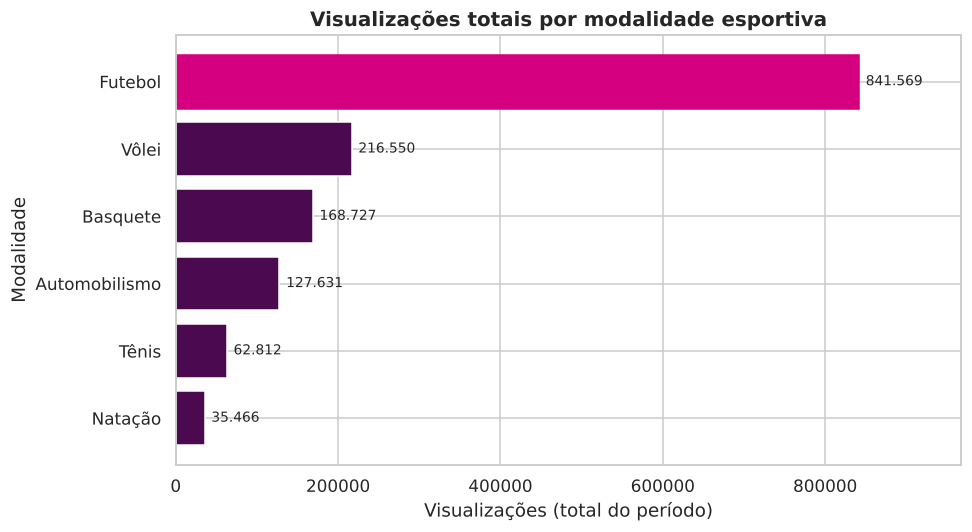

In [9]:
# ============================================================
# ETAPA 5 – VISUALIZAÇÕES
# ============================================================
# Gráfico 1 – Visualizações por modalidade
ordem = tab_mod.sort_values("visualizacoes")
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(ordem.index, ordem["visualizacoes"], color=PALETA[0])
barras[-1].set_color(PALETA[1])                     # destaca a líder
for b in barras:                                    # rótulos de valor
    ax.text(b.get_width() + ordem["visualizacoes"].max() * 0.01, b.get_y() + b.get_height() / 2,
            f"{b.get_width():,.0f}".replace(",", "."), va="center", fontsize=9)
ax.set_title("Visualizações totais por modalidade esportiva", fontsize=13, weight="bold")
ax.set_xlabel("Visualizações (total do período)")
ax.set_ylabel("Modalidade")
ax.set_xlim(0, ordem["visualizacoes"].max() * 1.15)
plt.tight_layout(); plt.show()

**Interpretação (Gráfico 1).** O futebol soma 841.569 visualizações, mais do que as outras cinco modalidades juntas (611.186). O vôlei vem em segundo lugar, com 216.550. É forte concentração de alcance, mas volume não é qualidade: o engajamento do futebol (3,24%) está abaixo da taxa geral do portal (3,81%), e modalidades de menor audiência, como Natação (7,67%) e Vôlei (5,61%), engajam mais por visualização.

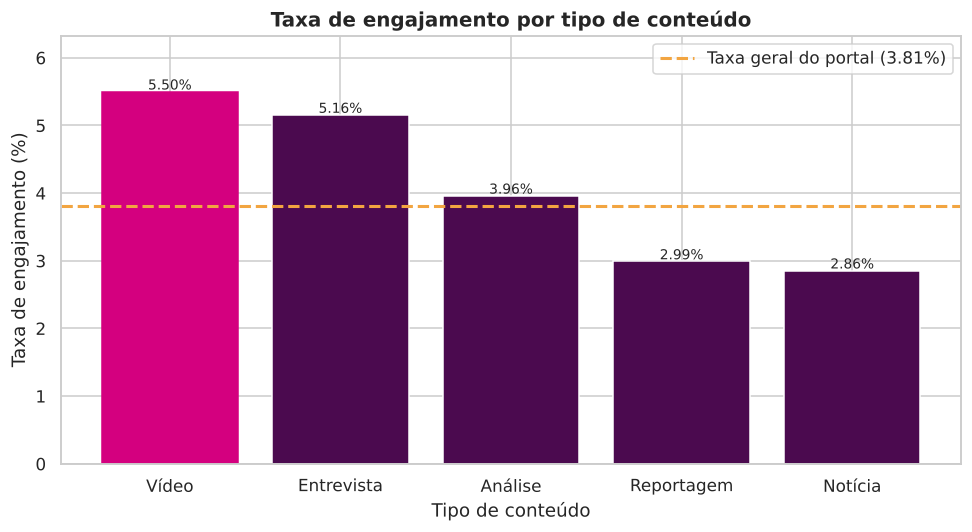

In [10]:
# Gráfico 2 – Taxa de engajamento por tipo de conteúdo
ordem = tab_tipo.sort_values("taxa_engajamento_pct", ascending=False)
media_geral = dados["total_interacoes"].sum() / dados["visualizacoes"].sum() * 100   # taxa geral recalculada
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(ordem.index, ordem["taxa_engajamento_pct"], color=PALETA[0])
barras[0].set_color(PALETA[1])
ax.axhline(media_geral, color=PALETA[3], linestyle="--", linewidth=2, label=f"Taxa geral do portal ({media_geral:.2f}%)")
for b in barras:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.03, f"{b.get_height():.2f}%", ha="center", fontsize=9)
ax.set_ylim(0, ordem["taxa_engajamento_pct"].max() * 1.15)   # folga para os rótulos
ax.set_title("Taxa de engajamento por tipo de conteúdo", fontsize=13, weight="bold")
ax.set_xlabel("Tipo de conteúdo")
ax.set_ylabel("Taxa de engajamento (%)")
ax.legend()
plt.tight_layout(); plt.show()

**Interpretação (Gráfico 2).** Vídeo (5,50%) e Entrevista (5,16%) ficam acima da taxa geral do portal (3,81%), enquanto Notícia (2,86%) e Reportagem (2,99%) ficam abaixo. Formatos que convidam à reação (imagem em movimento, voz de personagens) geram mais interação por visualização. Atenção: a Reportagem tem engajamento baixo, mas é a que mais converte (6,58%), então **engajamento sozinho não mede o valor do conteúdo**.

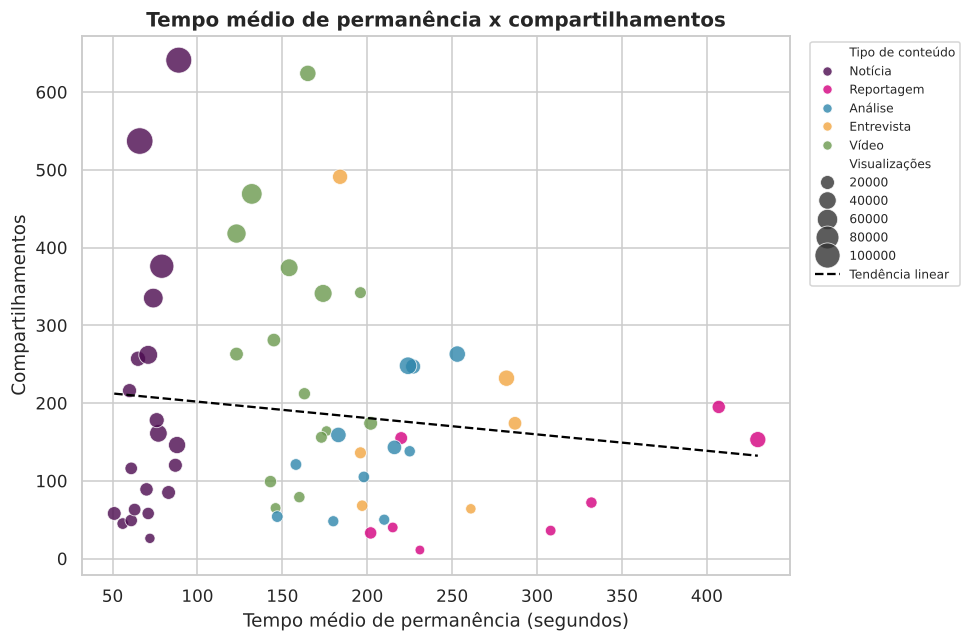

In [11]:
# Gráfico 3 – Dispersão: tempo médio x compartilhamentos
fig, ax = plt.subplots(figsize=(9, 6))
# Renomeia colunas só para a legenda ficar legível (a base "dados" não é alterada)
graf = dados.rename(columns={"tipo_conteudo": "Tipo de conteúdo", "visualizacoes": "Visualizações"})
sns.scatterplot(data=graf, x="tempo_medio_segundos", y="compartilhamentos", hue="Tipo de conteúdo",
                size="Visualizações", sizes=(40, 300), palette=PALETA[:5], alpha=0.8, edgecolor="white", ax=ax)

# Linha de tendência linear (apenas ilustrativa)
coef = np.polyfit(dados["tempo_medio_segundos"], dados["compartilhamentos"], 1)
xs = np.linspace(dados["tempo_medio_segundos"].min(), dados["tempo_medio_segundos"].max(), 100)
ax.plot(xs, np.polyval(coef, xs), color="black", linestyle="--", linewidth=1.5, label="Tendência linear")

ax.set_title("Tempo médio de permanência x compartilhamentos", fontsize=13, weight="bold")
ax.set_xlabel("Tempo médio de permanência (segundos)")
ax.set_ylabel("Compartilhamentos")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

**Interpretação (Gráfico 3).** Os pontos não formam tendência clara (r de Pearson = −0,12): mais tempo de permanência **não** vem acompanhado de mais compartilhamentos. Os maiores números de compartilhamentos aparecem em conteúdos de grande alcance (círculos maiores), o que indica que o **volume de visualizações pesa mais** do que o tempo de leitura. As reportagens ficam à direita (mais tempo), mas com poucos compartilhamentos em valor absoluto.

Semana de pico: 2026-10-04 -> 300,186 visualizações


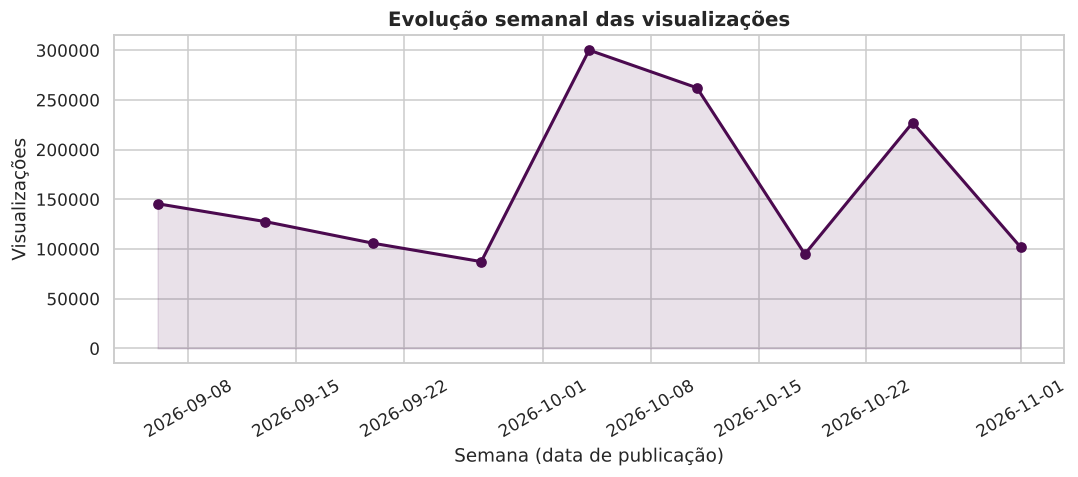

In [12]:
# Gráfico 4 (opcional) – Evolução semanal das visualizações
semanal = dados.set_index("data_publicacao")["visualizacoes"].resample("W").sum()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(semanal.index, semanal.values, marker="o", color=PALETA[0], linewidth=2)
ax.fill_between(semanal.index, semanal.values, alpha=0.12, color=PALETA[0])
ax.set_title("Evolução semanal das visualizações", fontsize=13, weight="bold")
ax.set_xlabel("Semana (data de publicação)")
ax.set_ylabel("Visualizações")
plt.xticks(rotation=30)
plt.tight_layout(); plt.show()
print("Semana de pico:", semanal.idxmax().date(), "->", f"{semanal.max():,.0f}", "visualizações")

**Interpretação (Gráfico 4, opcional).** As visualizações oscilam de semana para semana, com pico na semana de 04/10 (300.186) e sem tendência contínua de crescimento. Como o pico pode refletir poucos conteúdos de futebol de alto alcance, é necessário cruzar com o calendário esportivo antes de tirar conclusões (veja as limitações). As semanas das pontas são parciais.

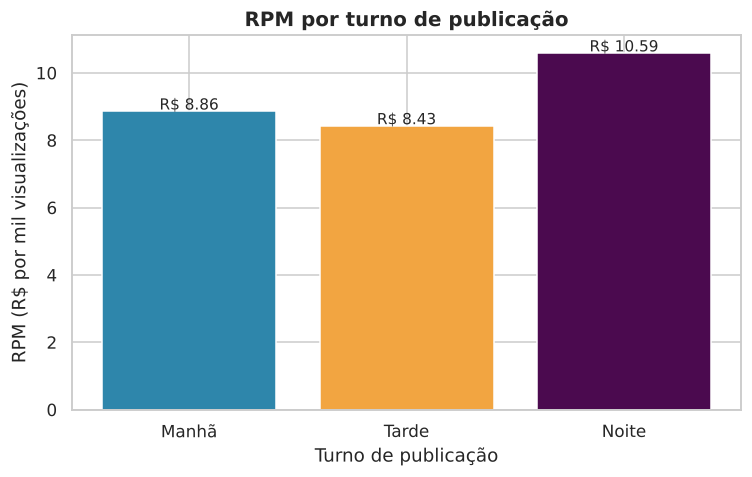

In [13]:
# Gráfico 5 (opcional) – RPM por turno de publicação (RPM recalculado)
ordem_turno = ["Manhã", "Tarde", "Noite"]
t = tab_turno.loc[ordem_turno]
fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(t.index, t["rpm"], color=[PALETA[2], PALETA[3], PALETA[0]])
for b in barras:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.05, f"R$ {b.get_height():.2f}", ha="center", fontsize=10)
ax.set_title("RPM por turno de publicação", fontsize=13, weight="bold")
ax.set_xlabel("Turno de publicação")
ax.set_ylabel("RPM (R$ por mil visualizações)")
plt.tight_layout(); plt.show()

**Interpretação (Gráfico 5, opcional).** O turno da noite tem o maior RPM (R$ 10,59), cerca de 26% acima do da tarde (R$ 8,43), com volume de visualizações praticamente igual (41,0% e 41,2% do total). A manhã fica em R$ 8,86. Uma **hipótese** é que a audiência noturna fique mais tempo na página ou veja mais anúncios; isso precisa ser testado, pois os dados não mostram o motivo.

### Questão 4 · Alcance × qualidade
Cortes usados: alto alcance = top 25% de visualizações; baixo engajamento = abaixo da mediana; menor alcance = abaixo da mediana de visualizações; alto engajamento = top 25%.

In [14]:
# ============================================================
# QUESTÃO 4 – ALCANCE x QUALIDADE (engajamento)
# ============================================================
p75_views = dados["visualizacoes"].quantile(0.75)
med_views = dados["visualizacoes"].median()
med_eng   = dados["taxa_engajamento_pct"].median()
p75_eng   = dados["taxa_engajamento_pct"].quantile(0.75)

cols_q4 = ["titulo", "modalidade", "tipo_conteudo", "portal", "turno_publicacao", "visualizacoes",
           "taxa_engajamento_pct", "taxa_recirculacao_pct", "tempo_medio_segundos"]

# Alto alcance (top 25% em views) e baixo engajamento (abaixo da mediana)
alto_alcance = dados[(dados["visualizacoes"] >= p75_views) & (dados["taxa_engajamento_pct"] < med_eng)]
# Menor alcance (abaixo da mediana de views) e alto engajamento (top 25%)
alto_engaj = dados[(dados["visualizacoes"] < med_views) & (dados["taxa_engajamento_pct"] >= p75_eng)]

print(f"Cortes: views P75 = {p75_views:,.0f} | views mediana = {med_views:,.0f} | "
      f"engajamento mediano = {med_eng:.2f}% | engajamento P75 = {p75_eng:.2f}%\n")
print("A) Alto alcance e baixo engajamento (maior alcance do grupo primeiro):")
display(alto_alcance.sort_values("visualizacoes", ascending=False)[cols_q4].head(3))
print("B) Menor alcance e maior engajamento (maior engajamento do grupo primeiro):")
display(alto_engaj.sort_values("taxa_engajamento_pct", ascending=False)[cols_q4].head(3))

Cortes: views P75 = 32,088 | views mediana = 17,554 | engajamento mediano = 3.88% | engajamento P75 = 5.10%

A) Alto alcance e baixo engajamento (maior alcance do grupo primeiro):


,titulo,modalidade,tipo_conteudo,portal,turno_publicacao,visualizacoes,taxa_engajamento_pct,taxa_recirculacao_pct,tempo_medio_segundos
0,Futebol: resultado e principais lances da rodada #01,Futebol,Notícia,App,Noite,112837,2.78,8.24,66
6,Futebol: resultado e principais lances da rodada #07,Futebol,Notícia,Portal Web,Noite,107442,2.45,8.01,89
16,Futebol: resultado e principais lances da rodada #17,Futebol,Notícia,Portal Web,Noite,91477,2.28,5.09,79


B) Menor alcance e maior engajamento (maior engajamento do grupo primeiro):


,titulo,modalidade,tipo_conteudo,portal,turno_publicacao,visualizacoes,taxa_engajamento_pct,taxa_recirculacao_pct,tempo_medio_segundos
40,Vôlei: melhores momentos em vídeo #41,Vôlei,Vídeo,YouTube,Tarde,10054,12.48,9.38,196
47,Natação: melhores momentos em vídeo #48,Natação,Vídeo,YouTube,Noite,4575,12.00,10.89,176
19,Natação: melhores momentos em vídeo #20,Natação,Vídeo,App,Tarde,5567,8.32,10.40,146


### Questão 4 · Alcance × qualidade
| Perfil | Conteúdo | Alcance | Engajamento | Observação |
|---|---|---|---|---|
| **Alto alcance, baixo engajamento** | *Futebol · Notícia #01* (noite, App) | 112.837 visualizações (maior da base) | 2,78% (mediana da base: 3,88%) | 66 s de permanência |
| **Menor alcance, alto engajamento** | *Vôlei · Vídeo #41* (tarde, YouTube) | 10.054 visualizações (abaixo da mediana de 17.554) | **12,48%** (maior da base) | 196 s de permanência |

**Hipóteses** (ainda não comprovadas):
1. A notícia de resultado atende a uma **consulta rápida**: o leitor entra, se informa e sai (66 s). Não há motivo para curtir, comentar ou compartilhar, e a audiência ampla inclui muitos leitores ocasionais.
2. O vídeo de melhores momentos de vôlei, no YouTube, atinge um **público já fã da modalidade**, em uma plataforma com botões de reação em destaque e conteúdo que convida a compartilhar. A audiência pequena e fiel eleva a taxa (e uma base pequena também a torna mais volátil).

A diferença pode vir do **formato**, do **canal** ou do **perfil do público**; para separar essas causas seria preciso um teste controlado.

### Questão 5 · Associação entre variáveis
Correlação de Pearson (linear) e de Spearman (por postos, mais robusta a valores extremos).

In [15]:
# ============================================================
# QUESTÃO 5 – ASSOCIAÇÃO ENTRE VARIÁVEIS
# ============================================================
# Pearson mede associação LINEAR; Spearman (ranks) é mais robusto a outliers e a relações não lineares
pares = [("tempo_medio_segundos", "compartilhamentos"), ("visualizacoes", "novos_assinantes")]
resultado = []
for a, b in pares:
    resultado.append({"par": f"{a} x {b}",
                      "pearson": dados[a].corr(dados[b], method="pearson"),
                      "spearman": dados[a].corr(dados[b], method="spearman")})
tab_corr = pd.DataFrame(resultado).set_index("par")
display(tab_corr)

# Ordem de grandeza para interpretar o r (regra prática, não é lei)
def forca(r):
    r = abs(r)
    return "muito fraca" if r < 0.2 else "fraca" if r < 0.4 else "moderada" if r < 0.6 else "forte" if r < 0.8 else "muito forte"
for par, linha in tab_corr.iterrows():
    print(f"{par}: Pearson = {linha['pearson']:.2f} ({forca(linha['pearson'])})")

# Controle de sanidade: o tamanho do conteúdo (views) também infla compartilhamentos e assinaturas
print("\nCorrelação entre visualizações e compartilhamentos:", round(dados["visualizacoes"].corr(dados["compartilhamentos"]), 2))

,pearson,spearman
par,,
tempo_medio_segundos x compartilhamentos,-0.12,-0.05
visualizacoes x novos_assinantes,0.39,0.54


tempo_medio_segundos x compartilhamentos: Pearson = -0.12 (muito fraca)
visualizacoes x novos_assinantes: Pearson = 0.39 (fraca)

Correlação entre visualizações e compartilhamentos: 0.78


### Questão 5 · Associação entre variáveis
| Par de variáveis | Pearson | Spearman | Leitura |
|---|---|---|---|
| Tempo médio × compartilhamentos | **−0,12** | −0,05 | Associação **muito fraca**; praticamente inexistente |
| Visualizações × novos assinantes | **0,39** | 0,54 | Fraca (Pearson) a moderada (Spearman): conteúdos mais vistos tendem a gerar mais assinaturas, mas com muita dispersão |

Visualizações e compartilhamentos têm correlação de 0,78: os compartilhamentos **em número absoluto** acompanham o tamanho da audiência, o que ajuda a explicar por que o tempo de permanência não os prevê.

**Por que correlação positiva não prova causalidade?**
- **Terceira variável (confusão):** um grande jogo ou decisão pode aumentar ao mesmo tempo as visualizações e as assinaturas; o conteúdo não "causou" as assinaturas, o **evento** causou ambos.
- **Causalidade reversa:** conteúdos que já geram assinaturas ou compartilhamentos podem ser mais promovidos pela home e pelas redes, ganhando visualizações por isso.
- **Amostra pequena e agregação:** com 60 conteúdos, poucos pontos extremos alteram o coeficiente; e a correlação descreve o conjunto, não o que aconteceria se mudássemos uma variável.

Só um **experimento** (por exemplo, teste A/B) permite afirmar causa e efeito.

### Evidências de apoio para os insights
A célula abaixo compara o **peso de cada tipo no alcance** com o **peso nas assinaturas**, verifica o engajamento por **portal** e mostra a **composição de formatos** por turno e modalidade, para não atribuir ao turno ou à modalidade o que pode ser efeito do formato.

In [16]:
# ============================================================
# EVIDÊNCIAS DE APOIO AOS INSIGHTS (participação no alcance x participação nas assinaturas)
# ============================================================
# 1) Quanto cada tipo pesa no alcance e quanto pesa nas assinaturas
part = tab_tipo[["visualizacoes", "novos_assinantes", "taxa_conversao_pct"]].copy()
part["%_das_views"]       = part["visualizacoes"] / part["visualizacoes"].sum() * 100
part["%_das_assinaturas"] = part["novos_assinantes"] / part["novos_assinantes"].sum() * 100
print("Participação no alcance x nas assinaturas, por tipo de conteúdo:")
display(part[["%_das_views", "%_das_assinaturas", "taxa_conversao_pct"]].sort_values("%_das_assinaturas", ascending=False))

# Taxa geral de engajamento do portal (recalculada pelas somas)
taxa_geral = dados["total_interacoes"].sum() / dados["visualizacoes"].sum() * 100
print(f"Taxa geral de engajamento do portal: {taxa_geral:.2f}%")
print(f"Reportagem + Análise: {part.loc[['Reportagem','Análise'], '%_das_views'].sum():.1f}% das views "
      f"e {part.loc[['Reportagem','Análise'], '%_das_assinaturas'].sum():.1f}% das assinaturas")

# 2) Engajamento por portal (o canal também pode explicar diferenças)
print("\nEngajamento por portal:")
display(consolidar(dados, "portal")[["conteudos", "visualizacoes", "taxa_engajamento_pct", "rpm"]])

# 3) Composição de formatos em cada turno e em cada modalidade (evita confundir turno/modalidade com formato)
print("Nº de conteúdos por turno x tipo:")
display(pd.crosstab(dados["turno_publicacao"], dados["tipo_conteudo"], margins=True))
print("Nº de conteúdos por modalidade x tipo:")
display(pd.crosstab(dados["modalidade"], dados["tipo_conteudo"], margins=True))

Participação no alcance x nas assinaturas, por tipo de conteúdo:


,%_das_views,%_das_assinaturas,taxa_conversao_pct
tipo_conteudo,,,
Análise,13.73,29.50,3.36
Reportagem,6.48,25.19,6.58
Notícia,48.75,19.64,1.06
Vídeo,24.14,17.34,1.59
Entrevista,6.90,8.33,2.49


Taxa geral de engajamento do portal: 3.81%
Reportagem + Análise: 20.2% das views e 54.7% das assinaturas

Engajamento por portal:


,conteudos,visualizacoes,taxa_engajamento_pct,rpm
portal,,,,
App,17,478609,3.84,9.25
Instagram,16,342733,3.53,8.80
Portal Web,10,328695,2.96,10.96
YouTube,17,302718,5.03,8.62


Nº de conteúdos por turno x tipo:


tipo_conteudo,Análise,Entrevista,Notícia,Reportagem,Vídeo,All
turno_publicacao,,,,,,
Manhã,2,1,5,1,2,11
Noite,5,3,7,2,7,24
Tarde,4,2,8,5,6,25
All,11,6,20,8,15,60


Nº de conteúdos por modalidade x tipo:


tipo_conteudo,Análise,Entrevista,Notícia,Reportagem,Vídeo,All
modalidade,,,,,,
Automobilismo,3,2,2,1,2,10
Basquete,0,0,5,2,1,8
Futebol,4,1,5,3,5,18
Natação,1,0,1,1,3,6
Tênis,2,0,3,1,0,6
Vôlei,1,3,4,0,4,12
All,11,6,20,8,15,60


### Questão 6 · Três insights editoriais
**Insight 1 · Alcance e assinatura são diferentes**
- **Evidência numérica:** Notícias concentram 48,7% das visualizações, mas só 19,6% das assinaturas (conversão de 1,06%). Reportagens têm 6,5% das visualizações e 25,2% das assinaturas (conversão de 6,58%). Reportagem + Análise somam 20,2% das visualizações e 54,7% das assinaturas.
- **Interpretação jornalística:** a notícia rápida resolve a necessidade do leitor em ~75 s e ele vai embora; a reportagem e a análise (336 s e 213 s) constroem a percepção de valor que leva à assinatura.
- **Relevância editorial:** pautas de profundidade são o principal motor de assinaturas e não devem ser cortadas por terem poucas visualizações; o portal depende delas e das notícias, cada uma com um papel.

**Insight 2 · O engajamento vem mais do formato e do canal do que do esporte dominante**
- **Evidência numérica:** Vídeo tem 5,50% de engajamento contra 2,86% da Notícia (~1,9 vez). O YouTube registra 5,03% contra 2,96% no Portal Web. O futebol, com 57,9% das visualizações, tem 3,24%, abaixo dos 3,81% do portal. Natação (7,67%) e Vôlei (5,61%) engajam mais, mas têm muitos vídeos (3 de 6 e 4 de 12 conteúdos): parte do efeito pode ser do formato, e não da modalidade.
- **Interpretação jornalística:** formatos audiovisuais e de voz convidam à reação; o futebol atrai muita gente de passagem, o que dilui a taxa.
- **Relevância editorial:** cobrir modalidades menores em vídeo ajuda a diversificar a pauta e a criar comunidades engajadas, mesmo com menos alcance. Com apenas 6 a 12 conteúdos por modalidade, é um sinal a validar, não uma conclusão.

**Insight 3 · Horário: a noite monetiza, a manhã parece converter**
- **Evidência numérica:** a noite tem RPM de R$ 10,59 contra R$ 8,43 da tarde (+26%) com volume parecido. A manhã tem a maior conversão (3,05% contra 1,91% da noite), mas só 11 conteúdos e 17,8% das visualizações.
- **Interpretação jornalística:** o consumo noturno (pós-jogo, lazer) é mais valioso para anunciantes; o leitor da manhã pode ser mais propenso a assinar após a leitura de conteúdos de contexto. É hipótese: a manhã tem proporção maior de notícias (45%), o que a princípio iria contra uma conversão alta, e por isso a amostra pequena exige cautela.
- **Relevância editorial:** pode-se testar a separação de objetivos por turno (monetização à noite, assinatura de manhã), sem abrir mão de publicar o que for relevante em qualquer horário.

### Questão 7 · Duas recomendações
**Recomendação 1 · Conectar notícias de grande audiência a conteúdos de profundidade**
| Item | Detalhe |
|---|---|
| **Ação proposta** | Nas notícias de futebol de alto alcance, inserir módulo de destaque "Leia a análise / reportagem" com a matéria aprofundada relacionada e chamada para assinatura. |
| **Evidência** | Notícia: recirculação de 7,05% e conversão de 1,06%; Análise: 11,83% e 3,36%; Reportagem: 10,93% e 6,58%. Notícias têm 48,7% das visualizações e 19,6% das assinaturas. |
| **Resultado esperado** | Aumentar a recirculação das notícias de 7,05% para pelo menos 9% e elevar as assinaturas por mil visualizações do grupo, sem prejudicar o tempo de leitura. |
| **Métrica de acompanhamento** | Taxa de recirculação das notícias; novos assinantes por mil visualizações; tempo médio na página. |
| **Forma de validação** | Teste A/B por 4 semanas: metade das notícias de futebol com o módulo e metade sem, comparando as taxas com teste de proporções. A comparação deve cuidar do evento esportivo (jogo de mesmo porte nos dois grupos). |

**Recomendação 2 · Piloto de vídeos curtos em modalidades menores**
| Item | Detalhe |
|---|---|
| **Ação proposta** | Produzir 2 vídeos de melhores momentos por semana de vôlei, natação e tênis, distribuídos no YouTube e no Instagram, com link para a análise relacionada no portal. |
| **Evidência** | Vídeo engaja 5,50% contra 2,86% da Notícia; YouTube 5,03% contra 2,96% do Portal Web; o *Vôlei · Vídeo #41* atingiu 12,48%. Ponto de atenção: o RPM de vídeo é o menor (R$ 8,20). |
| **Resultado esperado** | Taxa de engajamento acima de 5% nesses vídeos, mais compartilhamentos por mil visualizações e recirculação para o portal compensando o RPM menor. |
| **Métrica de acompanhamento** | Taxa de engajamento, compartilhamentos por mil visualizações, recirculação e RPM dos vídeos. |
| **Forma de validação** | Piloto de 4 semanas comparado às 4 semanas anteriores e a modalidades sem vídeo (grupo de controle), verificando se o resultado se repete em mais de uma modalidade. |

### Questão 8 · Limitações e dados adicionais necessários
1. **Origem do tráfego** (busca, redes sociais, notificação push, home, newsletter): sem ela não sabemos se o desempenho vem do conteúdo ou da distribuição.
2. **Calendário esportivo** (jogos, finais, grandes eventos): o desempenho de futebol e os picos semanais dependem fortemente do que estava acontecendo no esporte.
3. **Perfil da audiência** (novos × recorrentes, assinantes × não assinantes, faixa etária, região): necessário para saber para quem cada conteúdo funciona.
4. **Dados de assinantes** (retenção, cancelamento, valor ao longo do tempo) e **custo de produção** por conteúdo: uma assinatura de reportagem pode valer mais, mas custa mais para produzir.
5. **Destaque editorial** (posição na home, uso de push, tempo em destaque): conteúdos bem posicionados ganham alcance por isso.
6. **Limitações da própria base:** apenas 60 conteúdos em dois meses, poucos casos por grupo (algumas modalidades têm 6), atribuição de assinaturas possivelmente do tipo "último clique" e 1 valor de receita ausente.

## Conclusão (126 palavras)
A análise de 60 conteúdos mostra que alcance, engajamento e conversão medem coisas diferentes. O futebol concentra 57,9% das visualizações, mas seu engajamento (3,24%) fica abaixo da taxa geral do portal (3,81%). Vídeos e entrevistas interagem mais, enquanto reportagens e análises, com apenas 20,2% das visualizações, respondem por 54,7% dos novos assinantes. Decidir a pauta só pelo volume de cliques empobreceria a cobertura e reduziria a receita de assinaturas. Recomenda-se conectar notícias de grande audiência a conteúdos de profundidade e testar vídeos curtos de modalidades menores. As associações encontradas são correlações, não causas, e a base é pequena, de dois meses e sem calendário esportivo ou origem de tráfego. Os dados apoiam a decisão editorial, mas relevância, interesse público, diversidade e precisão seguem como critérios jornalísticos.

## Discussão de fechamento
- **O conteúdo mais visualizado também foi o mais relevante?** Não necessariamente. O *Futebol · Notícia #01* teve o maior alcance (112.837), mas engajamento (2,78%) e conversão (1,51%) abaixo do potencial de uma reportagem; a relevância jornalística inclui interesse público, e não só cliques.
- **Como a modalidade influencia a audiência?** O futebol domina o alcance (57,9%), mas as demais modalidades têm engajamento igual ou superior; parte disso pode ser efeito do formato (vídeo), então é preciso olhar modalidade e formato juntos.
- **Notícias rápidas e reportagens devem ter as mesmas métricas?** Não. Notícias fazem sentido por alcance e velocidade; reportagens por tempo de leitura, recirculação e conversão. Medir reportagem por visualizações a faria parecer fraca (6,5% das views) quando gera 25,2% das assinaturas.
- **Um conteúdo com poucas visualizações pode ter alto valor jornalístico?** Sim: pautas de interesse público, de modalidades pouco cobertas ou de fôlego investigativo podem ter nicho pequeno e grande impacto.
- **Quais os riscos de decidir só por cliques?** Empobrecer a diversidade da cobertura, favorecer o sensacionalismo e a pressa em detrimento da precisão, abandonar pautas de profundidade e modalidades menores, e reforçar o que já é popular.
- **Como equilibrar interesse público, qualidade e desempenho?** Usar métricas diferentes para objetivos diferentes (alcance, engajamento, assinatura, receita), manter uma cota editorial de pautas de interesse público independente do desempenho e testar hipóteses antes de mudar a pauta.

> Os dados devem apoiar a decisão editorial, mas não substituir os critérios jornalísticos de relevância, interesse público, diversidade, precisão e responsabilidade.

## Checklist do produto final
- [x] Notebook executado, com saídas visíveis
- [x] Base tratada (`dados`) e tabelas consolidadas por modalidade, tipo e turno
- [x] Cálculo das cinco métricas (coluna a coluna e passo a passo na Questão 2)
- [x] Três gráficos obrigatórios + dois opcionais, com interpretação
- [x] Três insights e duas recomendações
- [x] Conclusão entre 100 e 150 palavras
- [x] Registro das limitações da análise